# 🔍 License Plate Recognition — Inference Pipeline
### PP-OCRv5 vs PP-OCRv4: annotated results, batch processing and error analysis

This notebook loads the two recognition models fine-tuned in `PPOCR_License_Plate_Training.ipynb` and uses them on new images.

**Pipeline for each full car photo**
```
car photo ──► PP-OCR text detection (pretrained) ──► text boxes ──► fine-tuned recognizer ──► plate text + confidence
```
Each version uses its own detector: PP-OCRv5 uses `PP-OCRv5_server_det` and PP-OCRv4 uses `PP-OCRv4_server_det`, so the two complete pipelines are compared.

**Test data**
| Set | Source | Ground truth | Used for |
|---|---|---|---|
| Held-out plate crops | test split saved by the training notebook | plate text | accuracy, error analysis |
| Full car photos | [Car License Plate Detection](https://www.kaggle.com/datasets/andrewmvd/car-plate-detection) (Kaggle, CC0) — 433 images | plate bounding boxes, no text | detection + recognition on real scenes, batch processing |

The car photos come from a **different source** than the training data, so they also show how well the models generalize.

**Before running:** use a T4 GPU runtime, run the training notebook first, and add the `KAGGLE_API_TOKEN` Colab secret (same as in the training notebook).

**Contents**
1. Setup · 2. Load models · 3. Test images · 4. Inference & annotations · 5. Side-by-side comparison · 6. Accuracy on held-out plates · 7. Batch processing · 8. Error analysis · 9. Export · 10. Conclusions

## 1. Setup

In [1]:
import os, sys, re, time, random, shutil, difflib, collections
import xml.etree.ElementTree as ET

IN_COLAB = "google.colab" in sys.modules
if os.name == "nt":
    # Windows: make the CUDA DLLs installed by pip (nvidia-* packages) visible to Paddle and its subprocesses.
    import site
    for sp in site.getsitepackages():
        nv = os.path.join(sp, "nvidia")
        if os.path.isdir(nv):
            bins = [os.path.join(nv, d, "bin") for d in os.listdir(nv) if os.path.isdir(os.path.join(nv, d, "bin"))]
            os.environ["PATH"] = os.pathsep.join(bins + [os.environ["PATH"]])
print("Running in Colab:", IN_COLAB, "| Python", sys.version.split()[0])
!nvidia-smi --query-gpu=name,memory.total --format=csv

Running in Colab: False | Python 3.11.15


name, memory.total [MiB]
NVIDIA GeForce RTX 3050 6GB Laptop GPU, 6144 MiB


In [2]:
PADDLE_VERSION = "3.3.1"
PADDLEOCR_VERSION = "3.7.0"

if IN_COLAB:
    # ~1-2 GB download from Paddle's server; can take 5-15 min on Colab (progress bar shown)
    !pip install paddlepaddle-gpu=={PADDLE_VERSION} -i https://www.paddlepaddle.org.cn/packages/stable/cu126/
    !pip install -q paddleocr=={PADDLEOCR_VERSION} kaggle python-dotenv

In [3]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import paddle
from tqdm.auto import tqdm

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    ARTIFACT_DIR = "/content/drive/MyDrive/ppocr_license_plate"
else:
    ARTIFACT_DIR = os.path.abspath("artifacts")

WORK_DIR = "/content/ppocr_lp_inference" if IN_COLAB else os.path.abspath("work_inference")
OUT_DIR = os.path.join(WORK_DIR, "outputs")
os.makedirs(OUT_DIR, exist_ok=True)

MODEL_SIZE = "server"
DEVICE = "gpu:0" if paddle.device.cuda.device_count() > 0 else "cpu"
SEED = 42
N_SHOWCASE = 8     # images in the side-by-side gallery
N_BATCH = None     # None = all 433 car photos in batch processing

MODELS = {
    "PP-OCRv5": {"det": f"PP-OCRv5_{MODEL_SIZE}_det", "rec": f"PP-OCRv5_{MODEL_SIZE}_rec", "color": (46, 160, 67)},
    "PP-OCRv4": {"det": f"PP-OCRv4_{MODEL_SIZE}_det", "rec": f"PP-OCRv4_{MODEL_SIZE}_rec", "color": (31, 119, 180)},
}
for key, m in MODELS.items():
    m["rec_dir"] = os.path.join(ARTIFACT_DIR, "inference", m["rec"])
    assert os.path.exists(os.path.join(m["rec_dir"], "inference.yml")), \
        f"{m['rec_dir']} not found — run PPOCR_License_Plate_Training.ipynb first"
    print(f"{key}: detector {m['det']} (pretrained) + recognizer {m['rec_dir']}")
print("device:", DEVICE)

PP-OCRv5: detector PP-OCRv5_server_det (pretrained) + recognizer C:\Users\ritesh-18\Desktop\ritesh\benchmarking-tool\lynkit\artifacts\inference\PP-OCRv5_server_rec
PP-OCRv4: detector PP-OCRv4_server_det (pretrained) + recognizer C:\Users\ritesh-18\Desktop\ritesh\benchmarking-tool\lynkit\artifacts\inference\PP-OCRv4_server_rec
device: gpu:0


C:\Users\ritesh-18\Desktop\ritesh\benchmarking-tool\lynkit\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Load models
Each version is loaded twice:
- **Full pipeline** (`PaddleOCR`): the pretrained detector plus the fine-tuned recognizer, for full car photos. Document-orientation and unwarping modules are turned off because they are meant for scanned pages, not photos.
- **Recognizer only** (`TextRecognition`): reads plates that are already cropped. Comparing it with the full pipeline separates detection errors from recognition errors.

In [4]:
from paddleocr import PaddleOCR, TextRecognition

pipelines, recognizers = {}, {}
for key, m in MODELS.items():
    pipelines[key] = PaddleOCR(
        text_detection_model_name=m["det"],
        text_recognition_model_name=m["rec"],
        text_recognition_model_dir=m["rec_dir"],
        use_doc_orientation_classify=False,
        use_doc_unwarping=False,
        use_textline_orientation=False,
        device=DEVICE,
    )
    recognizers[key] = TextRecognition(model_name=m["rec"], model_dir=m["rec_dir"], device=DEVICE)
    # Warm-up so the first timed image doesn't include model initialisation.
    dummy = np.full((64, 256, 3), 255, np.uint8)
    pipelines[key].predict(dummy)
    recognizers[key].predict(input=dummy)
print("Loaded:", ", ".join(f"{k} pipeline + recognizer" for k in MODELS))

Creating model: ('PP-OCRv5_server_det', None, None)


Checking connectivity to the model hosters, this may take a while. To bypass this check, set `PADDLE_PDX_DISABLE_MODEL_SOURCE_CHECK` to `True`.


Using official model (PP-OCRv5_server_det), the model files will be automatically downloaded and saved in `C:\Users\ritesh-18\.paddlex\official_models\PP-OCRv5_server_det`.


[2026-10-25 21:21:25,927] [    INFO] _client.py:1084 - HTTP Request: GET https://huggingface.co/api/agent-harnesses "HTTP/1.1 200 OK"


[2026-10-25 21:21:26,292] [    INFO] _client.py:1084 - HTTP Request: GET https://huggingface.co/api/models/PaddlePaddle/PP-OCRv5_server_det/revision/main "HTTP/1.1 200 OK"


...

Fetching 6 files:  83%|████████▎ | 5/6 [00:14<00:00, 15.21it/s]

Fetching 6 files: 100%|██████████| 6/6 [00:24<00:00,  5.66s/it]

Fetching 6 files: 100%|██████████| 6/6 [00:24<00:00,  4.08s/it]

Creating model: ('PP-OCRv4_server_rec', 'C:\\Users\\ritesh-18\\Desktop\\ritesh\\benchmarking-tool\\lynkit\\artifacts\\inference\\PP-OCRv4_server_rec', None)


Loaded: PP-OCRv5 pipeline + recognizer, PP-OCRv4 pipeline + recognizer


## 3. Test images
- **Held-out plate crops:** the test split the training notebook saved to Drive. None of these plates were used in training or validation.
- **Full car photos:** downloaded from Kaggle. Their Pascal-VOC XML files give the plate box(es) for each photo, which are used to check whether the detector found the plate.

Held-out plate crops: 67


Dataset URL: https://www.kaggle.com/datasets/andrewmvd/car-plate-detection


Full car photos: 433 (471 annotated plates)


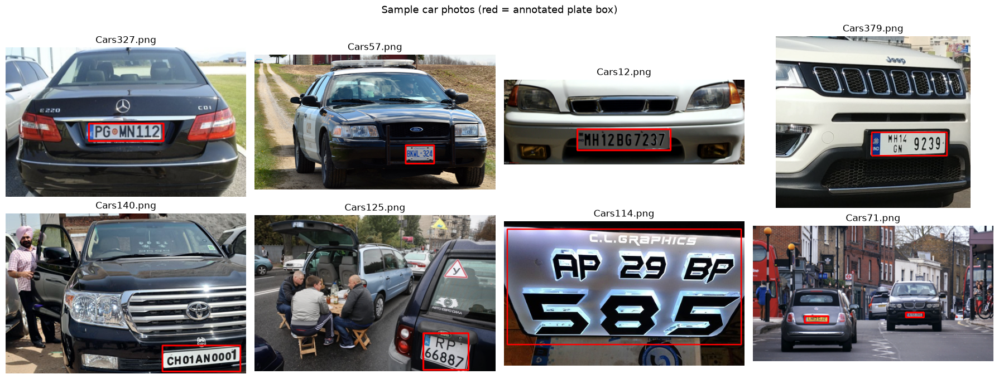

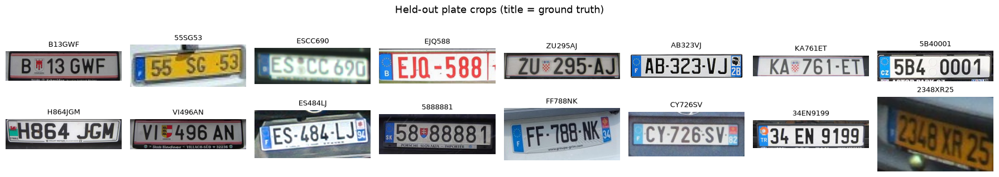

In [5]:
TEST_DIR = os.path.join(ARTIFACT_DIR, "test_data")
crop_items = []
with open(os.path.join(TEST_DIR, "test.txt"), encoding="utf-8") as f:
    for line in f:
        img, label = line.rstrip("\n").split("\t")
        crop_items.append((os.path.join(TEST_DIR, img), label))
print(f"Held-out plate crops: {len(crop_items)}")

if IN_COLAB:
    from google.colab import userdata
    os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")
else:
    from dotenv import load_dotenv
    load_dotenv(".env")
from kaggle.api.kaggle_api_extended import KaggleApi

SCENE_DIR = os.path.join(WORK_DIR, "car_plate_detection")
if not os.path.isdir(SCENE_DIR):
    api = KaggleApi()
    api.authenticate()
    api.dataset_download_files("andrewmvd/car-plate-detection", path=SCENE_DIR, unzip=True)

def read_boxes(xml_path):
    boxes = []
    for obj in ET.parse(xml_path).getroot().iter("object"):
        bb = obj.find("bndbox")
        boxes.append(tuple(int(float(bb.find(k).text)) for k in ("xmin", "ymin", "xmax", "ymax")))
    return boxes

scenes = []
for name in sorted(os.listdir(os.path.join(SCENE_DIR, "images")), key=lambda n: int(re.sub(r"\D", "", n) or 0)):
    xml = os.path.join(SCENE_DIR, "annotations", os.path.splitext(name)[0] + ".xml")
    if os.path.exists(xml):
        scenes.append({"name": name, "path": os.path.join(SCENE_DIR, "images", name), "gt_boxes": read_boxes(xml)})
SHOWCASE = random.Random(SEED).sample(scenes, N_SHOWCASE)
print(f"Full car photos: {len(scenes)} ({sum(len(s['gt_boxes']) for s in scenes)} annotated plates)")

fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, s in zip(axes.flat, SHOWCASE):
    img = cv2.cvtColor(cv2.imread(s["path"]), cv2.COLOR_BGR2RGB)
    for x1, y1, x2, y2 in s["gt_boxes"]:
        cv2.rectangle(img, (x1, y1), (x2, y2), (255, 0, 0), 2)
    ax.imshow(img)
    ax.set_title(s["name"])
    ax.axis("off")
fig.suptitle("Sample car photos (red = annotated plate box)", fontsize=13)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 8, figsize=(18, 3.2))
for ax, (path, label) in zip(axes.flat, random.Random(SEED).sample(crop_items, 16)):
    ax.imshow(cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB))
    ax.set_title(label, fontsize=9)
    ax.axis("off")
fig.suptitle("Held-out plate crops (title = ground truth)", fontsize=13)
plt.tight_layout()
plt.show()

## 4. Inference and annotations
`read_scene` runs one pipeline on a car photo and links its text boxes to the annotated plate:
- A detected text box belongs to a plate when its centre lies inside the plate box, padded by 15%.
- Plates are sometimes detected as several pieces (e.g. `AB` and `1234`). The pieces are joined from left to right, and their mean confidence becomes the plate's confidence.
- The text is normalised to `A–Z0–9`, the same alphabet as the labels.

`annotate` draws the results:
- **thick coloured box:** the plate, with its recognized text and confidence
- **thin orange box:** other text the detector found
- **red box:** a plate the detector missed

Cars327.png: 3 text boxes, 310 ms
   box=[55, 99, 92, 109]  text='E220'  score=0.948
   box=[318, 94, 343, 105]  text='CD1'  score=0.916
   box=[144, 126, 258, 153]  text='PGMN112'  score=0.999


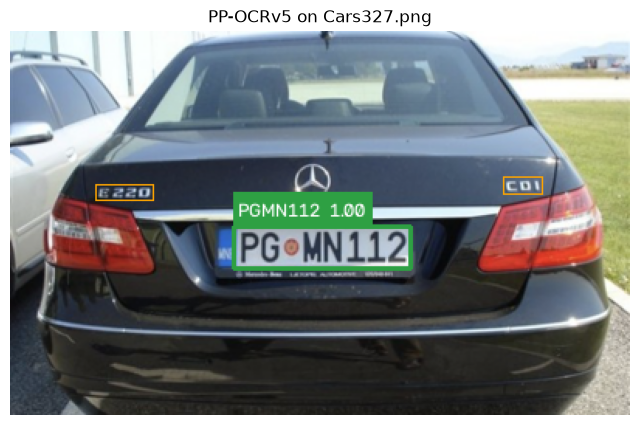

In [6]:
def res_json(result):
    return result.json["res"]

def clean(text):
    return re.sub(r"[^A-Z0-9]", "", text.upper())

def poly_to_box(poly):
    xs, ys = zip(*poly)
    return [int(min(xs)), int(min(ys)), int(max(xs)), int(max(ys))]

def center_in(box, region, pad=0.15):
    x1, y1, x2, y2 = region
    px, py = (x2 - x1) * pad, (y2 - y1) * pad
    cx, cy = (box[0] + box[2]) / 2, (box[1] + box[3]) / 2
    return x1 - px <= cx <= x2 + px and y1 - py <= cy <= y2 + py

def read_scene(key, scene):
    start = time.perf_counter()
    r = res_json(pipelines[key].predict(scene["path"])[0])
    ms = (time.perf_counter() - start) * 1000
    boxes = r.get("rec_boxes")
    if boxes is None or len(boxes) == 0:
        boxes = [poly_to_box(p) for p in r.get("rec_polys", [])]
    dets = [{"box": [int(v) for v in b], "text": t, "score": float(s)}
            for b, t, s in zip(boxes, r["rec_texts"], r["rec_scores"])]
    plates = []
    for gt in scene["gt_boxes"]:
        hits = sorted((d for d in dets if center_in(d["box"], gt)), key=lambda d: d["box"][0])
        plates.append({
            "gt": gt, "hits": hits, "detected": bool(hits),
            "text": clean("".join(d["text"] for d in hits)),
            "score": float(np.mean([d["score"] for d in hits])) if hits else 0.0,
        })
    return {"dets": dets, "plates": plates, "ms": ms}

def draw_label(img, text, x, y_top, y_bottom, color, scale, thick):
    (w, h), _ = cv2.getTextSize(text, cv2.FONT_HERSHEY_SIMPLEX, scale, thick)
    y = y_top - 6 if y_top - h - 10 > 0 else y_bottom + h + 8
    cv2.rectangle(img, (x, y - h - 5), (x + w + 6, y + 4), color, -1)
    cv2.putText(img, text, (x + 3, y), cv2.FONT_HERSHEY_SIMPLEX, scale, (255, 255, 255), thick, cv2.LINE_AA)

def annotate(scene, result, color):
    img = cv2.cvtColor(cv2.imread(scene["path"]), cv2.COLOR_BGR2RGB)
    k = max(img.shape[:2]) / 600
    thick, font = max(2, round(2 * k)), 0.6 * k
    plate_boxes = [d["box"] for p in result["plates"] for d in p["hits"]]
    for d in result["dets"]:
        if d["box"] not in plate_boxes:
            x1, y1, x2, y2 = d["box"]
            cv2.rectangle(img, (x1, y1), (x2, y2), (255, 165, 0), max(1, thick // 2))
    for p in result["plates"]:
        if p["hits"]:
            x1 = min(d["box"][0] for d in p["hits"]); y1 = min(d["box"][1] for d in p["hits"])
            x2 = max(d["box"][2] for d in p["hits"]); y2 = max(d["box"][3] for d in p["hits"])
            cv2.rectangle(img, (x1, y1), (x2, y2), color, thick)
            draw_label(img, f"{p['text'] or '?'}  {p['score']:.2f}", x1, y1, y2, color, font, max(1, thick // 2))
        else:
            x1, y1, x2, y2 = p["gt"]
            cv2.rectangle(img, (x1, y1), (x2, y2), (220, 40, 40), thick)
            draw_label(img, "plate not detected", x1, y1, y2, (220, 40, 40), font, max(1, thick // 2))
    return img

demo = SHOWCASE[0]
demo_result = read_scene("PP-OCRv5", demo)
print(f"{demo['name']}: {len(demo_result['dets'])} text boxes, {demo_result['ms']:.0f} ms")
for d in demo_result["dets"]:
    print(f"   box={d['box']}  text={d['text']!r}  score={d['score']:.3f}")
plt.figure(figsize=(8, 5))
plt.imshow(annotate(demo, demo_result, MODELS["PP-OCRv5"]["color"]))
plt.title(f"PP-OCRv5 on {demo['name']}")
plt.axis("off")
plt.show()

## 5. Side-by-side comparison: PP-OCRv5 vs PP-OCRv4
Each row shows the original photo, the PP-OCRv5 result, and the PP-OCRv4 result. Each panel title gives the plate text, confidence and processing time.

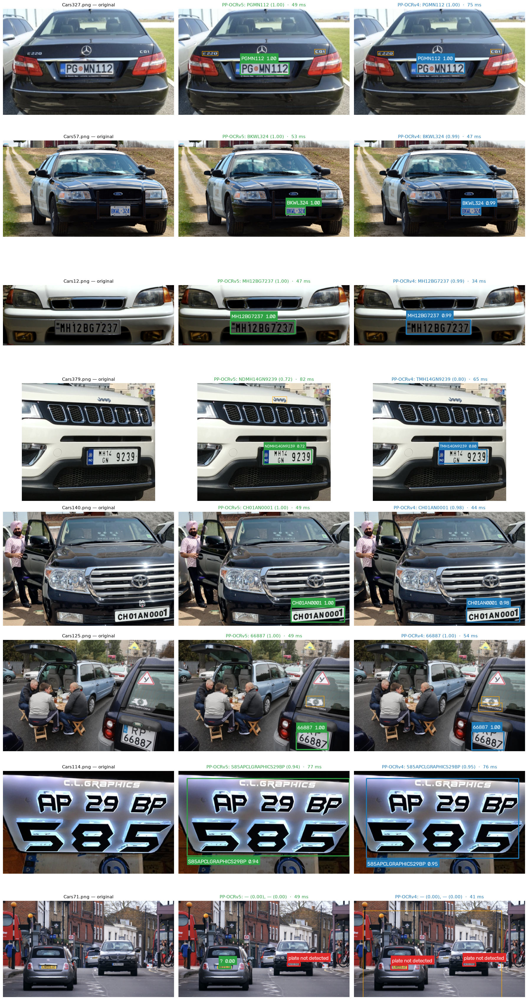

In [7]:
showcase_results = {s["name"]: {key: read_scene(key, s) for key in MODELS} for s in SHOWCASE}

fig, axes = plt.subplots(len(SHOWCASE), 3, figsize=(18, 4.3 * len(SHOWCASE)))
for row, s in zip(axes, SHOWCASE):
    row[0].imshow(cv2.cvtColor(cv2.imread(s["path"]), cv2.COLOR_BGR2RGB))
    row[0].set_title(f"{s['name']} — original", fontsize=11)
    for ax, key in zip(row[1:], MODELS):
        res = showcase_results[s["name"]][key]
        ax.imshow(annotate(s, res, MODELS[key]["color"]))
        plates = ", ".join(f"{p['text'] or '—'} ({p['score']:.2f})" for p in res["plates"])
        ax.set_title(f"{key}: {plates}  ·  {res['ms']:.0f} ms", fontsize=11,
                     color=np.array(MODELS[key]["color"]) / 255)
    for ax in row:
        ax.axis("off")
plt.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "side_by_side.png"), dpi=100)
plt.show()

## 6. Accuracy on held-out plates
On the held-out crops, the ground-truth text is known, so accuracy can be measured exactly.
The official (not fine-tuned) recognizers are included as a reference to show what fine-tuning changed. Their output is also normalised to `A–Z0–9`, so they aren't penalised for reading separators.

- **accuracy:** share of plates read exactly right
- **char accuracy:** 1 − character error rate (edit distance ÷ plate length)

Using official model (PP-OCRv5_server_rec), the model files will be automatically downloaded and saved in `C:\Users\ritesh-18\.paddlex\official_models\PP-OCRv5_server_rec`.


[2026-10-25 21:23:07,537] [    INFO] _client.py:1084 - HTTP Request: GET https://huggingface.co/api/models/PaddlePaddle/PP-OCRv5_server_rec/revision/main "HTTP/1.1 200 OK"


[2026-10-25 21:23:07,776] [    INFO] _client.py:1084 - HTTP Request: GET https://huggingface.co/api/models/PaddlePaddle/PP-OCRv5_server_rec/tree/b26c3587fda8da3c8ec0ce357214b4d661ff1558?recursive=true&expand=false "HTTP/1.1 200 OK"


Fetching 6 files:   0%|          | 0/6 [00:00<?, ?it/s]

[2026-10-25 21:23:08,046] [    INFO] _client.py:1084 - HTTP Request: HEAD https://huggingface.co/PaddlePaddle/PP-OCRv5_server_rec/resolve/b26c3587fda8da3c8ec0ce357214b4d661ff1558/README.md "HTTP/1.1 307 Temporary Redirect"


...

PP-OCRv4 official:  60%|█████▉    | 40/67 [00:00<00:00, 93.82it/s]

PP-OCRv4 official:  75%|███████▍  | 50/67 [00:00<00:00, 92.41it/s]

PP-OCRv4 official:  90%|████████▉ | 60/67 [00:00<00:00, 88.70it/s]

PP-OCRv4 official: 100%|██████████| 67/67 [00:00<00:00, 91.99it/s]

,model,weights,accuracy,char_accuracy,mean_confidence,median_ms
0,PP-OCRv4,fine-tuned,95.5%,98.1%,0.979,10.4
1,PP-OCRv4,official,79.1%,94.9%,0.916,10.3
2,PP-OCRv5,fine-tuned,95.5%,98.1%,0.984,24.2
3,PP-OCRv5,official,76.1%,94.5%,0.895,9.6


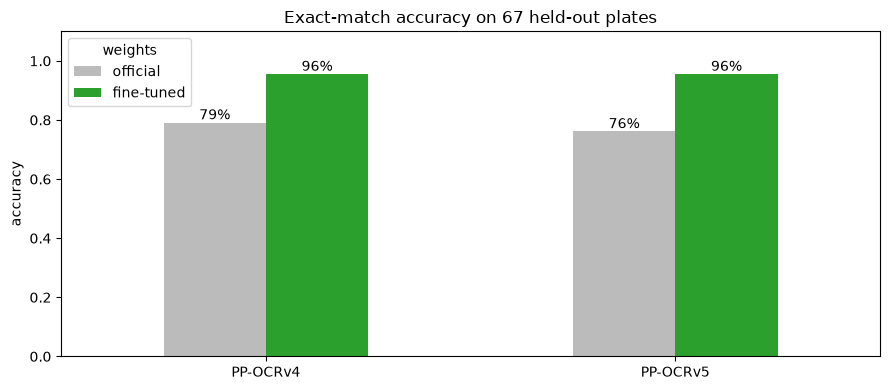

In [8]:
def levenshtein(a, b):
    prev = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        cur = [i]
        for j, cb in enumerate(b, 1):
            cur.append(min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + (ca != cb)))
        prev = cur
    return prev[-1]

variants = {("fine-tuned", key): recognizers[key] for key in MODELS}
for key, m in MODELS.items():
    variants[("official", key)] = TextRecognition(model_name=m["rec"], device=DEVICE)
    variants[("official", key)].predict(input=crop_items[0][0])  # warm-up

rows = []
for (weights, key), rec in variants.items():
    for path, label in tqdm(crop_items, desc=f"{key} {weights}"):
        start = time.perf_counter()
        r = res_json(rec.predict(input=path)[0])
        ms = (time.perf_counter() - start) * 1000
        pred = clean(r["rec_text"])
        h, w = cv2.imread(path).shape[:2]
        rows.append({"model": key, "weights": weights, "image": path, "label": label, "raw": r["rec_text"],
                     "pred": pred, "score": float(r["rec_score"]), "correct": pred == label,
                     "cer": levenshtein(pred, label) / len(label), "ms": ms, "width": w, "length": len(label)})
crop_df = pd.DataFrame(rows)

crop_table = crop_df.groupby(["model", "weights"]).agg(
    accuracy=("correct", "mean"), char_accuracy=("cer", lambda s: 1 - s.mean()),
    mean_confidence=("score", "mean"), median_ms=("ms", "median")).reset_index()
display(crop_table.style.format({"accuracy": "{:.1%}", "char_accuracy": "{:.1%}",
                                 "mean_confidence": "{:.3f}", "median_ms": "{:.1f}"}))

fig, ax = plt.subplots(figsize=(9, 4))
crop_table.pivot(index="model", columns="weights", values="accuracy")[["official", "fine-tuned"]] \
    .plot.bar(ax=ax, rot=0, color=["#bbbbbb", "#2ca02c"])
for container in ax.containers:
    ax.bar_label(container, fmt=lambda v: f"{v:.0%}")
ax.set(title=f"Exact-match accuracy on {len(crop_items)} held-out plates", ylim=(0, 1.1), ylabel="accuracy", xlabel="")
plt.tight_layout()
plt.show()

C:\Users\ritesh-18\AppData\Local\Temp\ipykernel_6084\3629380935.py:2: Pandas4Warning: Setting a new column on a DataFrame with a MultiIndex using a key that is not a full-length tuple is deprecated and will raise in a future version. Use a full-length tuple key instead.
  ft["label"] = crop_df.drop_duplicates("image").set_index("image")["label"]


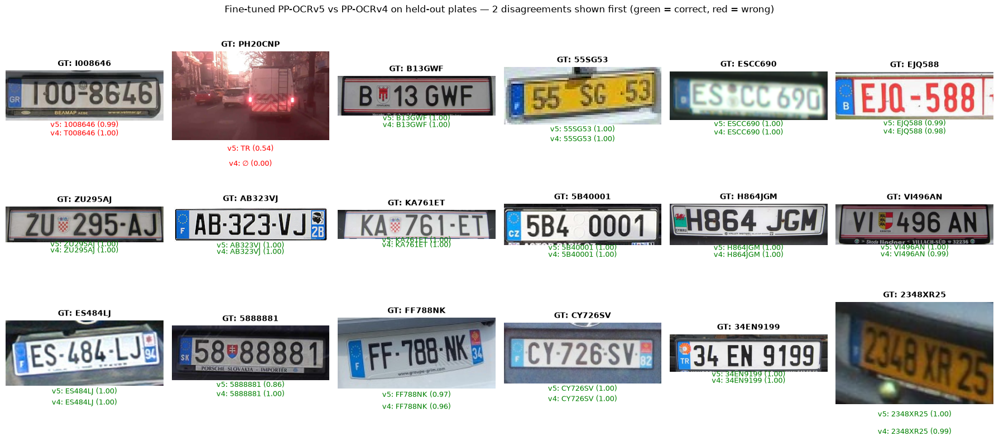

In [9]:
ft = crop_df[crop_df.weights == "fine-tuned"].pivot(index="image", columns="model", values=["pred", "score", "correct"])
ft["label"] = crop_df.drop_duplicates("image").set_index("image")["label"]
disagree = ft[ft[("pred", "PP-OCRv5")] != ft[("pred", "PP-OCRv4")]]
gallery = list(disagree.index) + [i for i in random.Random(SEED).sample(list(ft.index), len(ft)) if i not in disagree.index]

fig, axes = plt.subplots(3, 6, figsize=(18, 8))
for ax, img in zip(axes.flat, gallery[:18]):
    ax.imshow(cv2.cvtColor(cv2.imread(img), cv2.COLOR_BGR2RGB))
    ax.set_title(f"GT: {ft.loc[img, ('label', '')]}", fontsize=10, fontweight="bold")
    for i, key in enumerate(MODELS):
        ok = ft.loc[img, ("correct", key)]
        ax.text(0.5, -0.12 - 0.17 * i, f"{key[-2:]}: {ft.loc[img, ('pred', key)] or '∅'} ({ft.loc[img, ('score', key)]:.2f})",
                transform=ax.transAxes, ha="center", fontsize=9, color="green" if ok else "red")
    ax.axis("off")
fig.suptitle(f"Fine-tuned PP-OCRv5 vs PP-OCRv4 on held-out plates — {len(disagree)} disagreements shown first "
             "(green = correct, red = wrong)", fontsize=12)
plt.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "crop_comparison.png"), dpi=100)
plt.show()

## 7. Batch processing
Run both full pipelines on every car photo and save an annotated image per model.
For each annotated plate, the plate region is also cropped from the photo and read by the recognizer alone (`crop_text`). If the full pipeline's text differs from `crop_text`, the detector's box was the cause.

In [10]:
batch_scenes = scenes if N_BATCH is None else scenes[:N_BATCH]
for key in MODELS:
    os.makedirs(os.path.join(OUT_DIR, "annotated", key), exist_ok=True)

batch_rows = []
for s in tqdm(batch_scenes, desc="car photos"):
    img_bgr = cv2.imread(s["path"])
    H, W = img_bgr.shape[:2]
    for key in MODELS:
        res = read_scene(key, s)
        cv2.imwrite(os.path.join(OUT_DIR, "annotated", key, s["name"]),
                    cv2.cvtColor(annotate(s, res, MODELS[key]["color"]), cv2.COLOR_RGB2BGR))
        for i, p in enumerate(res["plates"]):
            x1, y1, x2, y2 = p["gt"]
            crop = img_bgr[max(0, y1):min(H, y2), max(0, x1):min(W, x2)]
            c = res_json(recognizers[key].predict(input=crop)[0]) if crop.size else {"rec_text": "", "rec_score": 0.0}
            batch_rows.append({
                "image": s["name"], "plate": i, "model": key, "detected": p["detected"], "text": p["text"],
                "score": p["score"], "text_boxes": len(res["dets"]), "ms": res["ms"],
                "crop_text": clean(c["rec_text"]), "crop_score": float(c["rec_score"]),
                "plate_width": x2 - x1,
            })
batch_df = pd.DataFrame(batch_rows)
batch_df.to_csv(os.path.join(OUT_DIR, "batch_results.csv"), index=False)
print(f"Processed {batch_df.image.nunique()} images / {len(batch_df) // len(MODELS)} plates per model")

car photos:   0%|          | 0/433 [00:00<?, ?it/s]

car photos:   0%|          | 1/433 [00:00<01:06,  6.51it/s]

car photos:   0%|          | 2/433 [00:00<01:07,  6.37it/s]

car photos:   1%|          | 3/433 [00:00<01:10,  6.10it/s]

car photos:   1%|          | 4/433 [00:00<01:01,  6.95it/s]

...

car photos: 100%|█████████▉| 431/433 [01:07<00:00,  6.56it/s]

car photos: 100%|█████████▉| 432/433 [01:07<00:00,  6.80it/s]

car photos: 100%|██████████| 433/433 [01:07<00:00,  7.01it/s]

car photos: 100%|██████████| 433/433 [01:07<00:00,  6.41it/s]

Processed 433 images / 471 plates per model


,images,plates,plate detection rate,mean confidence (detected),pipeline text = crop text,median latency (ms/image),mean text boxes / image
model,,,,,,,
PP-OCRv4,433,471,0.819533,0.946295,0.619171,47.0,2.1
PP-OCRv5,433,471,0.815287,0.943955,0.625000,40.8,1.9


PP-OCRv5 and PP-OCRv4 read the same text on 69.5% of the 371 plates both detected.


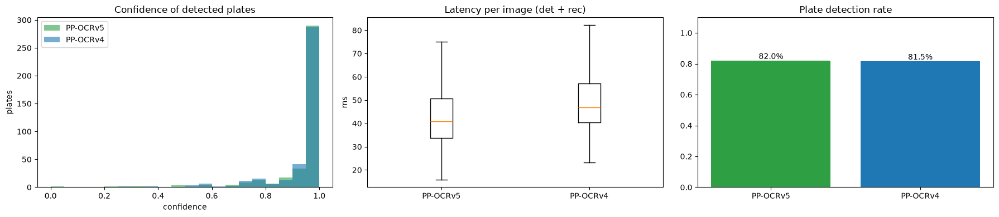

In [11]:
per_image = batch_df.drop_duplicates(["image", "model"])
detected = batch_df[batch_df.detected]
wide = batch_df.pivot_table(index=["image", "plate"], columns="model", values="text", aggfunc="first")
both = batch_df.pivot_table(index=["image", "plate"], columns="model", values="detected", aggfunc="first").all(axis=1)

stats = pd.DataFrame({
    "images": per_image.groupby("model").size(),
    "plates": batch_df.groupby("model").size(),
    "plate detection rate": batch_df.groupby("model")["detected"].mean(),
    "mean confidence (detected)": detected.groupby("model")["score"].mean(),
    "pipeline text = crop text": detected.assign(same=detected.text == detected.crop_text).groupby("model")["same"].mean(),
    "median latency (ms/image)": per_image.groupby("model")["ms"].median(),
    "mean text boxes / image": per_image.groupby("model")["text_boxes"].mean(),
})
display(stats.style.format({c: "{:.1%}" for c in ["plate detection rate", "pipeline text = crop text"]})
        .format({c: "{:.3f}" for c in ["mean confidence (detected)"]})
        .format({c: "{:.1f}" for c in ["median latency (ms/image)", "mean text boxes / image"]}))
agree = (wide.loc[both, "PP-OCRv5"] == wide.loc[both, "PP-OCRv4"]).mean()
print(f"PP-OCRv5 and PP-OCRv4 read the same text on {agree:.1%} of the {both.sum()} plates both detected.")

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for key in MODELS:
    color = np.array(MODELS[key]["color"]) / 255
    axes[0].hist(detected[detected.model == key]["score"], bins=20, range=(0, 1), alpha=0.6, label=key, color=color)
axes[0].set(title="Confidence of detected plates", xlabel="confidence", ylabel="plates")
axes[0].legend()
axes[1].boxplot([per_image[per_image.model == k]["ms"] for k in MODELS], showfliers=False)
axes[1].set_xticks(range(1, len(MODELS) + 1), list(MODELS))
axes[1].set(title="Latency per image (det + rec)", ylabel="ms")
bars = axes[2].bar(list(MODELS), stats["plate detection rate"], color=[np.array(m["color"]) / 255 for m in MODELS.values()])
axes[2].bar_label(bars, fmt=lambda v: f"{v:.1%}")
axes[2].set(title="Plate detection rate", ylim=(0, 1.1))
plt.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "batch_summary.png"), dpi=120)
plt.show()

## 8. Error analysis
### 8.1 Mistakes on held-out plates
Every plate that a fine-tuned model read wrong, with what it predicted and how confident it was.

PP-OCRv5: 3 errors out of 67 plates
PP-OCRv4: 3 errors out of 67 plates


,model,label,pred,raw,score,cer,image
0,PP-OCRv4,PH20CNP,,,0.000,1.00,PH20CNP.png
1,PP-OCRv4,YB75711,YBZ5711,YBZ5711,0.995,0.14,YB75711.png
2,PP-OCRv4,I008646,T008646,T008646,0.996,0.14,I008646.png
3,PP-OCRv5,PH20CNP,TR,TR,0.537,1.00,PH20CNP.png
4,PP-OCRv5,I008646,1008646,1008646,0.986,0.14,I008646.png
5,PP-OCRv5,YB75711,YBZ5711,YBZ5711,0.999,0.14,YB75711.png


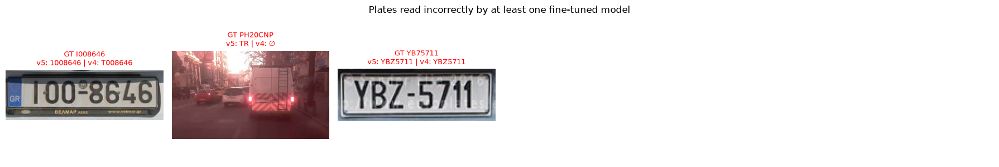

In [12]:
ft_df = crop_df[crop_df.weights == "fine-tuned"]
errors = ft_df[~ft_df.correct]
for key in MODELS:
    e = errors[errors.model == key]
    print(f"{key}: {len(e)} errors out of {len(ft_df[ft_df.model == key])} plates")
display(errors[["model", "label", "pred", "raw", "score", "cer"]]
        .assign(image=errors.image.map(os.path.basename))
        .sort_values(["model", "score"]).reset_index(drop=True)
        .style.format({"score": "{:.3f}", "cer": "{:.2f}"}))

wrong_imgs = errors.drop_duplicates("image")["image"].tolist()[:12]
if wrong_imgs:
    cols = 6
    rows_ = (len(wrong_imgs) + cols - 1) // cols
    fig, axes = plt.subplots(rows_, cols, figsize=(18, 3 * rows_), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, img in zip(axes.flat, wrong_imgs):
        ax.imshow(cv2.cvtColor(cv2.imread(img), cv2.COLOR_BGR2RGB))
        label = ft_df[ft_df.image == img]["label"].iloc[0]
        preds = " | ".join(f"{k[-2:]}: {ft_df[(ft_df.image == img) & (ft_df.model == k)]['pred'].iloc[0] or '∅'}" for k in MODELS)
        ax.set_title(f"GT {label}\n{preds}", fontsize=9, color="red")
    fig.suptitle("Plates read incorrectly by at least one fine-tuned model", fontsize=12)
    plt.tight_layout()
    plt.show()

### 8.2 Character confusions
Each prediction is aligned with its label. The most frequent substitutions show which characters each model confuses, e.g. `0→O` or `8→B`.
`X→∅` means a character was missed and `∅→X` means an extra character was added.

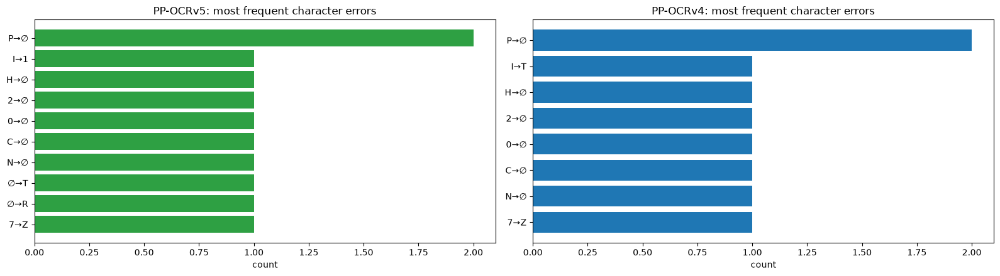

In [13]:
def confusions(df):
    counts = collections.Counter()
    for label, pred in zip(df.label, df.pred):
        for op, i1, i2, j1, j2 in difflib.SequenceMatcher(None, label, pred).get_opcodes():
            if op == "equal":
                continue
            gt, pr = label[i1:i2], pred[j1:j2]
            if len(gt) == len(pr):
                counts.update(f"{a}→{b}" for a, b in zip(gt, pr))
            else:
                counts.update(f"{a}→∅" for a in gt)
                counts.update(f"∅→{b}" for b in pr)
    return counts

fig, axes = plt.subplots(1, len(MODELS), figsize=(16, 4.5))
for ax, key in zip(axes, MODELS):
    top = confusions(ft_df[ft_df.model == key]).most_common(12)
    if top:
        names, values = zip(*top)
        ax.barh(names[::-1], values[::-1], color=np.array(MODELS[key]["color"]) / 255)
    ax.set(title=f"{key}: most frequent character errors", xlabel="count")
plt.tight_layout()
plt.show()

### 8.3 When do errors happen?
- **Plate length and image width:** do long plates or low-resolution crops cause more mistakes?
- **Confidence:** is the model less confident when it is wrong? If so, a confidence threshold can flag plates for manual review. The accuracy–coverage curve shows the trade-off: keep only the most confident X% of predictions, and see how accurate they are.

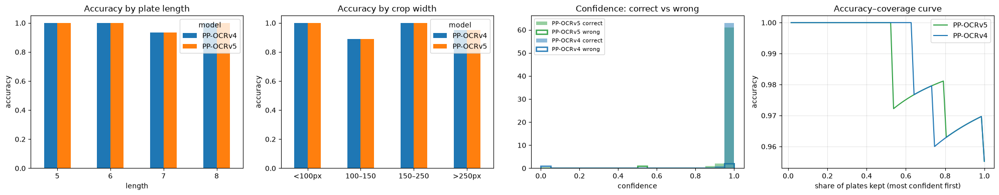

In [14]:
ft_df = ft_df.assign(width_bin=pd.cut(ft_df.width, [0, 100, 150, 250, 10_000], labels=["<100px", "100–150", "150–250", ">250px"]))
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
ft_df.pivot_table(index="length", columns="model", values="correct", aggfunc="mean").plot.bar(ax=axes[0], rot=0)
axes[0].set(title="Accuracy by plate length", ylabel="accuracy", ylim=(0, 1.05))
ft_df.pivot_table(index="width_bin", columns="model", values="correct", aggfunc="mean", observed=False).plot.bar(ax=axes[1], rot=0)
axes[1].set(title="Accuracy by crop width", ylabel="accuracy", ylim=(0, 1.05), xlabel="")

for key in MODELS:
    sub = ft_df[ft_df.model == key]
    color = np.array(MODELS[key]["color"]) / 255
    axes[2].hist(sub[sub.correct]["score"], bins=20, range=(0, 1), alpha=0.5, color=color, label=f"{key} correct")
    axes[2].hist(sub[~sub.correct]["score"], bins=20, range=(0, 1), alpha=0.9, color=color, histtype="step", lw=2,
                 label=f"{key} wrong")
    ranked = sub.sort_values("score", ascending=False)["correct"].to_numpy()
    coverage = np.arange(1, len(ranked) + 1) / len(ranked)
    axes[3].plot(coverage, np.cumsum(ranked) / np.arange(1, len(ranked) + 1), label=key, color=color)
axes[2].set(title="Confidence: correct vs wrong", xlabel="confidence")
axes[2].legend(fontsize=8)
axes[3].set(title="Accuracy–coverage curve", xlabel="share of plates kept (most confident first)", ylabel="accuracy")
axes[3].legend()
axes[3].grid(alpha=0.3)
plt.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "error_analysis.png"), dpi=120)
plt.show()

### 8.4 Failures on full car photos
Car photos have no text labels, so each plate is sorted by what happened to it:
- **not detected:** the detector found no text box on the plate
- **detection cut the plate:** the full pipeline's text differs from the recognizer reading the annotated crop, so the detected box was partial or merged with other text
- **low confidence:** detected and consistent, but confidence < 0.8
- **confident read:** detected, consistent and confident

Below are photos where PP-OCRv5 and PP-OCRv4 disagree.

outcome,confident read,low confidence,detection cut the plate,not detected
model,,,,
PP-OCRv4,50.5%,0.2%,31.2%,18.0%
PP-OCRv5,50.5%,0.4%,30.6%,18.5%


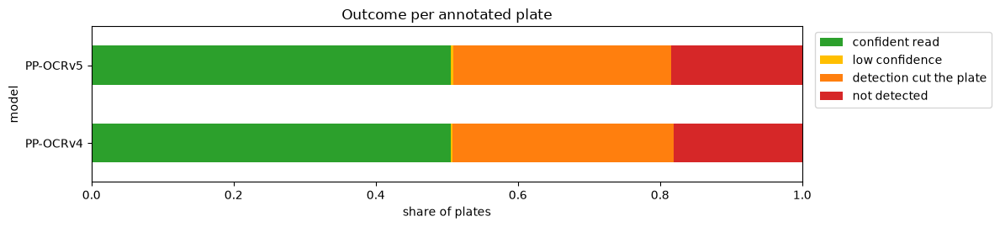

Photos where the two pipelines disagree: 135


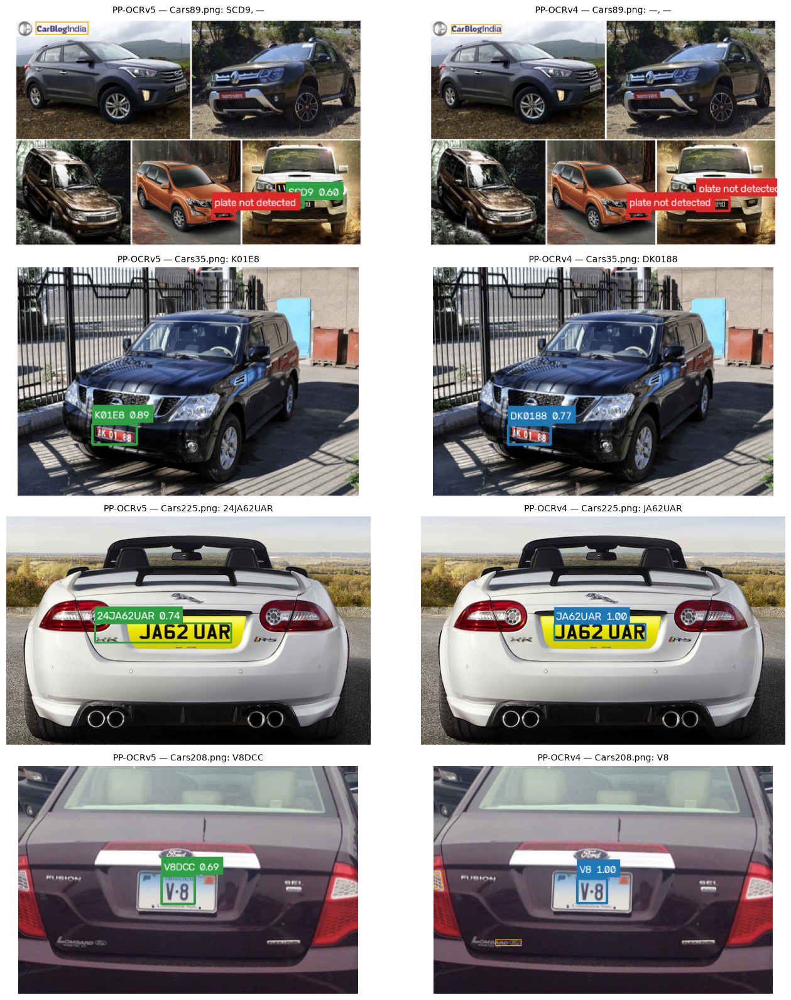

In [15]:
def outcome(r):
    if not r.detected:
        return "not detected"
    if r.text != r.crop_text:
        return "detection cut the plate"
    if r.score < 0.8:
        return "low confidence"
    return "confident read"

batch_df["outcome"] = batch_df.apply(outcome, axis=1)
order = ["confident read", "low confidence", "detection cut the plate", "not detected"]
outcomes = batch_df.pivot_table(index="model", columns="outcome", values="image", aggfunc="count", fill_value=0) \
    .reindex(columns=order, fill_value=0)
display((outcomes.T / outcomes.sum(axis=1)).T.style.format("{:.1%}"))
ax = (outcomes.T / outcomes.sum(axis=1)).T.plot.barh(stacked=True, figsize=(12, 2.8),
                                                    color=["#2ca02c", "#ffbf00", "#ff7f0e", "#d62728"])
ax.set(title="Outcome per annotated plate", xlabel="share of plates", xlim=(0, 1))
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

disagree_imgs = sorted({i for (i, _), a, b in zip(wide.index, wide["PP-OCRv5"], wide["PP-OCRv4"]) if a != b},
                       key=lambda n: int(re.sub(r"\D", "", n) or 0))
print(f"Photos where the two pipelines disagree: {len(disagree_imgs)}")
examples = random.Random(SEED).sample(disagree_imgs, min(4, len(disagree_imgs)))
if examples:
    fig, axes = plt.subplots(len(examples), 2, figsize=(14, 4 * len(examples)), squeeze=False)
    for row, name in zip(axes, examples):
        for ax, key in zip(row, MODELS):
            ax.imshow(cv2.cvtColor(cv2.imread(os.path.join(OUT_DIR, "annotated", key, name)), cv2.COLOR_BGR2RGB))
            texts = batch_df[(batch_df.image == name) & (batch_df.model == key)]["text"].tolist()
            ax.set_title(f"{key} — {name}: {', '.join(t or '—' for t in texts)}", fontsize=10)
            ax.axis("off")
    plt.tight_layout()
    plt.show()

In [16]:
print("Key insights (computed from the results above)")
for key in MODELS:
    sub = ft_df[ft_df.model == key]
    top = confusions(sub).most_common(3)
    wrong_conf, right_conf = sub[~sub.correct]["score"].mean(), sub[sub.correct]["score"].mean()
    o = outcomes.loc[key] / outcomes.loc[key].sum()
    print(f"\n{key}")
    print(f"  • Held-out plates: {sub.correct.mean():.1%} exact, {1 - sub.cer.mean():.1%} character accuracy.")
    if top:
        print(f"  • Most common character errors: {', '.join(f'{c} ({n}x)' for c, n in top)}.")
    if not np.isnan(wrong_conf):
        print(f"  • Mean confidence {right_conf:.2f} when correct vs {wrong_conf:.2f} when wrong.")
    print(f"  • Car photos: {o['not detected']:.1%} plates not detected, {o['detection cut the plate']:.1%} cut by detection, "
          f"{o['confident read']:.1%} read with confidence ≥ 0.8.")

Key insights (computed from the results above)

PP-OCRv5
  • Held-out plates: 95.5% exact, 98.1% character accuracy.
  • Most common character errors: P→∅ (2x), I→1 (1x), H→∅ (1x).
  • Mean confidence 0.99 when correct vs 0.84 when wrong.
  • Car photos: 18.5% plates not detected, 30.6% cut by detection, 50.5% read with confidence ≥ 0.8.

PP-OCRv4
  • Held-out plates: 95.5% exact, 98.1% character accuracy.
  • Most common character errors: P→∅ (2x), I→T (1x), H→∅ (1x).
  • Mean confidence 0.99 when correct vs 0.66 when wrong.
  • Car photos: 18.0% plates not detected, 31.2% cut by detection, 50.5% read with confidence ≥ 0.8.


## 9. Export results
The outputs are saved to Drive under `ppocr_license_plate/inference_outputs/`:
- annotated images for both models
- CSV files with every prediction
- the summary plots

In [17]:
crop_df.to_csv(os.path.join(OUT_DIR, "heldout_predictions.csv"), index=False)
stats.to_csv(os.path.join(OUT_DIR, "batch_summary.csv"))
crop_table.to_csv(os.path.join(OUT_DIR, "heldout_accuracy.csv"), index=False)

archive = shutil.make_archive(os.path.join(WORK_DIR, "inference_outputs"), "zip", OUT_DIR)
dest = os.path.join(ARTIFACT_DIR, "inference_outputs")
shutil.copytree(OUT_DIR, dest, dirs_exist_ok=True)
shutil.copy2(archive, ARTIFACT_DIR)
print("Saved to", dest)
print("Zip:", os.path.join(ARTIFACT_DIR, os.path.basename(archive)), f"({os.path.getsize(archive) / 1e6:.1f} MB)")
for f in sorted(os.listdir(OUT_DIR)):
    print("  ", f)

Saved to C:\Users\ritesh-18\Desktop\ritesh\benchmarking-tool\lynkit\artifacts\inference_outputs
Zip: C:\Users\ritesh-18\Desktop\ritesh\benchmarking-tool\lynkit\artifacts\inference_outputs.zip (177.6 MB)
   annotated
   batch_results.csv
   batch_summary.csv
   batch_summary.png
   crop_comparison.png
   error_analysis.png
   heldout_accuracy.csv
   heldout_predictions.csv
   side_by_side.png


## 10. Conclusions
*Run on a local NVIDIA RTX 3050 Laptop GPU (6 GB).*

**Recognition on held-out plates is strong and the two versions are tied.** Both fine-tuned models read **95.5%** of the 67 held-out plates exactly, with 98.1% character accuracy. The official models score 76.1% (v5) and 79.1% (v4) even after their output is reduced to `A–Z0–9`, so fine-tuning adds about 17–19 points. Both fine-tuned models fail on the same three plates:
- `PH20CNP` is unreadable for both: PP-OCRv4 returns nothing and PP-OCRv5 returns `TR`.
- `YB75711` is read as `YBZ5711` (7→Z).
- `I008646` is read as `T008646` (v4) and `1008646` (v5). The `I` and `1` confusion is ambiguous even for people on many plate fonts.

**Confidence is a useful error signal.** Mean confidence is 0.99 on correct reads, against 0.84 (v5) and 0.66 (v4) on wrong ones. A confidence threshold could route doubtful plates to manual review, and it would work better for PP-OCRv4.

**On real car photos, detection is the weak link, not recognition.** Across 471 annotated plates in 433 photos:
- about **82%** of plates are found by the general-purpose text detector (81.5% v5, 82.0% v4).
- **50.5%** are read cleanly with confidence ≥ 0.8.
- about **31%** have a detected box that differs from the plate. Either it covers only part of the plate (two-line plates such as `MH14 GN 9239`), or it merges in nearby text (dealer frames such as `C.L.GRAPHICS`, stray symbols).
- about **18%** are missed entirely, mostly small, distant or steeply angled plates.

The photos also include many non-European plates, such as Indian two-line plates, which the training set does not contain. PP-OCRv5 and PP-OCRv4 return the same text on 69.5% of the plates both detect.

**Speed.** The median full pipeline (detection + recognition) takes 40.8 ms per image for PP-OCRv5 and 47.0 ms for PP-OCRv4.

**Recommendation.** Deploy **PP-OCRv5**: it is equally accurate, slightly faster and smaller. The largest gain would come from improving detection rather than recognition. Fine-tuning `PP-OCRv5_server_det` on the 433 annotated plate boxes would address both missed plates and partial boxes. After that, more training plates from more countries (especially two-line formats) and a confidence threshold for manual review would help.